In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = "/content/drive/MyDrive/hausa_news_project"
os.makedirs(PROJECT_DIR, exist_ok=True)
os.chdir(PROJECT_DIR)

print("Working directory:", os.getcwd())
print("Files:", os.listdir("."))
required = ["train.csv", "val.csv", "test.csv", "labels.json"]
missing = [f for f in required if f not in os.listdir(".")]
print("Missing files:", missing if missing else "none, ready to go")

Mounted at /content/drive
Working directory: /content/drive/MyDrive/hausa_news_project
Files: ['train.csv', 'val.csv', 'test.csv', 'labels.json', 'baseline_C_tuning.csv', 'w2v_matrix.pt', 'ft_matrix.pt', 'ckpt', 'neural_learning_curves.png', 'neural_confusion_matrix.png', 'neural_errors.csv', 'best_neural.pt', 'preds', 'best_transformer', 'transformer_confusion_matrix.png', 'transformer_errors.csv', 'model_comparison.png', 'per_class_f1.png', 'confidence_hist.png', 'error_annotation.csv', 'space', 'baseline_tuning.csv', 'results.json', 'baseline_confusion_matrix.png', 'baseline_errors.csv']
Missing files: none, ready to go


In [ ]:
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline, make_pipeline, make_union
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             f1_score, classification_report, confusion_matrix)

SEED = 42
np.random.seed(SEED)

train = pd.read_csv("train.csv")
val   = pd.read_csv("val.csv")
test  = pd.read_csv("test.csv")
meta  = json.load(open("labels.json"))
id2label = {int(k): v for k, v in meta["id2label"].items()}
label_names = [id2label[i] for i in range(len(id2label))]

X_train, y_train = train["text_clean"], train["label_id"]
X_val,   y_val   = val["text_clean"],   val["label_id"]
X_test,  y_test  = test["text_clean"],  test["label_id"]
print(len(train), len(val), len(test), label_names)

# ---------- reusable evaluation functions (we reuse these for every model) ----------
RESULTS_FILE = "results.json"
try:
    RESULTS = json.load(open(RESULTS_FILE))
except FileNotFoundError:
    RESULTS = []

def compute_metrics(y_true, y_pred):
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {"accuracy": accuracy_score(y_true, y_pred),
            "macro_precision": p, "macro_recall": r, "macro_f1": f1,
            "weighted_f1": f1_score(y_true, y_pred, average="weighted")}

def log_result(name, val_metrics, test_metrics=None, notes=""):
    row = {"model": name, "notes": notes,
           **{f"val_{k}": round(v, 4) for k, v in val_metrics.items()}}
    if test_metrics:
        row.update({f"test_{k}": round(v, 4) for k, v in test_metrics.items()})
    RESULTS[:] = [r for r in RESULTS if r["model"] != name]   # overwrite same name
    RESULTS.append(row)
    json.dump(RESULTS, open(RESULTS_FILE, "w"), indent=2)

def full_report(name, y_true, y_pred, X_text, prefix="final"):
    print(f"\n===== {name} =====")
    print(classification_report(y_true, y_pred, target_names=label_names, digits=3))
    cm = confusion_matrix(y_true, y_pred)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    plt.figure(figsize=(8, 6.5))
    sns.heatmap(cm_norm, annot=cm, fmt="d", cmap="Blues",
                xticklabels=label_names, yticklabels=label_names)
    plt.xlabel("Predicted"); plt.ylabel("True")
    plt.title(f"Confusion matrix: {name}\n(colour = row-normalised, numbers = counts)")
    plt.tight_layout()
    plt.savefig(f"{prefix}_confusion_matrix.png", dpi=150)
    plt.show()
    # save misclassified examples for error analysis
    err = pd.DataFrame({"text": X_text.values,
                        "true": [id2label[i] for i in y_true],
                        "pred": [id2label[i] for i in y_pred]})
    err = err[err["true"] != err["pred"]]
    err.to_csv(f"{prefix}_errors.csv", index=False)
    print(f"Misclassified: {len(err)} / {len(y_true)} -> saved {prefix}_errors.csv")
    return err

2219 317 637 ['business', 'entertainment', 'health', 'politics', 'religion', 'sports', 'technology']


In [ ]:
word_tfidf = lambda: TfidfVectorizer(lowercase=True, ngram_range=(1, 2),
                                     min_df=2, sublinear_tf=True)
char_tfidf = lambda: TfidfVectorizer(lowercase=True, analyzer="char_wb",
                                     ngram_range=(2, 5), min_df=2, sublinear_tf=True)

candidates = {
    "TFIDF-word + LogReg":      make_pipeline(word_tfidf(), LogisticRegression(max_iter=2000, C=10, random_state=SEED)),
    "TFIDF-word + LinearSVM":   make_pipeline(word_tfidf(), LinearSVC(C=1.0, random_state=SEED)),
    "TFIDF-word + CompNB":      make_pipeline(word_tfidf(), ComplementNB(alpha=0.3)),
    "TFIDF-char + LinearSVM":   make_pipeline(char_tfidf(), LinearSVC(C=1.0, random_state=SEED)),
    "TFIDF-word+char + LinearSVM": make_pipeline(make_union(word_tfidf(), char_tfidf()),
                                                 LinearSVC(C=1.0, random_state=SEED)),
    "TFIDF-word + LinearSVM (balanced)": make_pipeline(word_tfidf(),
                                                       LinearSVC(C=1.0, class_weight="balanced", random_state=SEED)),
}

fitted = {}
for name, pipe in candidates.items():
    t0 = time.time()
    pipe.fit(X_train, y_train)
    m = compute_metrics(y_val, pipe.predict(X_val))
    fitted[name] = pipe
    log_result(name, m, notes="baseline")
    print(f"{name:38s} val acc={m['accuracy']:.3f}  macro-F1={m['macro_f1']:.3f}  ({time.time()-t0:.1f}s)")

TFIDF-word + LogReg                    val acc=0.918  macro-F1=0.912  (16.6s)
TFIDF-word + LinearSVM                 val acc=0.905  macro-F1=0.897  (3.2s)
TFIDF-word + CompNB                    val acc=0.909  macro-F1=0.897  (4.0s)
TFIDF-char + LinearSVM                 val acc=0.899  macro-F1=0.891  (14.0s)
TFIDF-word+char + LinearSVM            val acc=0.909  macro-F1=0.901  (17.7s)
TFIDF-word + LinearSVM (balanced)      val acc=0.909  macro-F1=0.902  (3.4s)


         kind     C  accuracy  macro_precision  macro_recall  macro_f1  weighted_f1
       LogReg  10.0    0.9180           0.9125        0.9122    0.9115       0.9181
       LogReg  30.0    0.9148           0.9082        0.9092    0.9080       0.9152
       LogReg 100.0    0.9148           0.9082        0.9092    0.9080       0.9152
Word+char SVM   1.0    0.9085           0.9014        0.9022    0.9011       0.9089
       LogReg   3.0    0.9085           0.9028        0.9008    0.9008       0.9085
Word+char SVM  10.0    0.9022           0.8939        0.8957    0.8941       0.9026
Word+char SVM   3.0    0.9022           0.8939        0.8957    0.8941       0.9026
Word+char SVM   0.3    0.9022           0.8949        0.8944    0.8938       0.9026
Word+char SVM   0.1    0.8991           0.8924        0.8895    0.8899       0.8992
       LogReg   1.0    0.8959           0.8918        0.8852    0.8867       0.8952
VAL : {'accuracy': 0.918, 'macro_precision': 0.912, 'macro_recall': 0.912, '

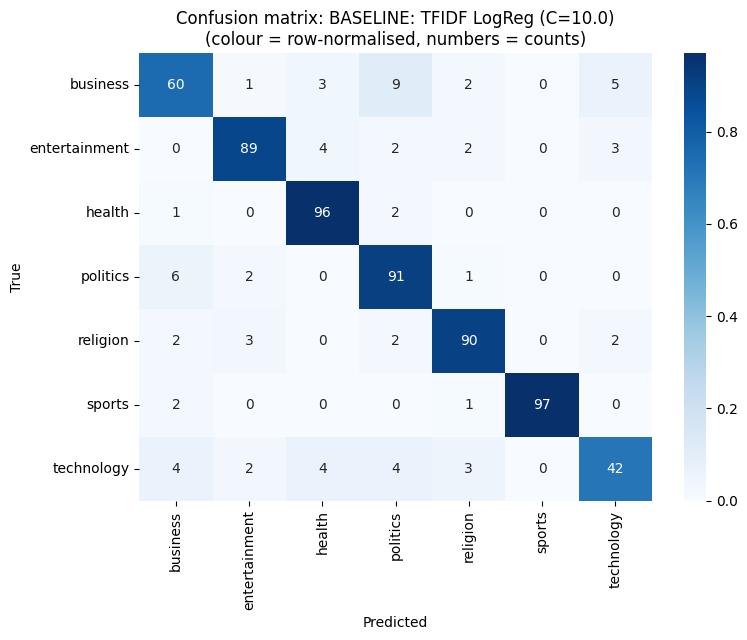

Misclassified: 72 / 637 -> saved baseline_errors.csv


In [ ]:
from sklearn.dummy import DummyClassifier

d = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
log_result("Majority class", compute_metrics(y_val, d.predict(X_val)), notes="trivial reference")

def make_pipe(kind, C):
    if kind == "LogReg":
        return make_pipeline(word_tfidf(), LogisticRegression(max_iter=3000, C=C, random_state=SEED))
    return make_pipeline(make_union(word_tfidf(), char_tfidf()), LinearSVC(C=C, random_state=SEED))

grid = [("LogReg", C) for C in [1, 3, 10, 30, 100]] + [("Word+char SVM", C) for C in [0.1, 0.3, 1, 3, 10]]
rows = []
for kind, C in grid:
    p = make_pipe(kind, C).fit(X_train, y_train)
    m = compute_metrics(y_val, p.predict(X_val))
    rows.append({"kind": kind, "C": C, **{k: round(v, 4) for k, v in m.items()}})
tune_df = pd.DataFrame(rows).sort_values("macro_f1", ascending=False)
print(tune_df.to_string(index=False)); tune_df.to_csv("baseline_tuning.csv", index=False)

best = tune_df.iloc[0]                      # chosen on VALIDATION macro-F1 only
final_baseline = make_pipe(best["kind"], float(best["C"])).fit(X_train, y_train)
val_m = compute_metrics(y_val, final_baseline.predict(X_val))
test_pred = final_baseline.predict(X_test); test_m = compute_metrics(y_test, test_pred)
name = f"BASELINE: TFIDF {best['kind']} (C={best['C']})"
log_result(name, val_m, test_m, notes="final baseline, chosen by val macro-F1")
print("VAL :", {k: round(v, 3) for k, v in val_m.items()})
print("TEST:", {k: round(v, 3) for k, v in test_m.items()})
errors_baseline = full_report(name, y_test, test_pred, X_test, prefix="baseline")

In [ ]:
pd.set_option("display.max_colwidth", 160)
print(errors_baseline.groupby(["true", "pred"]).size().sort_values(ascending=False).head(10))
print(errors_baseline.sample(min(8, len(errors_baseline)), random_state=SEED)
      .assign(text=lambda d: d["text"].str[:160]))

pd.DataFrame(RESULTS)

true           pred      
business       politics      10
politics       business       7
business       health         6
               technology     5
entertainment  technology     4
technology     business       4
               politics       4
entertainment  health         3
               politics       3
technology     health         3
dtype: int64
                                                                                                                                                                text  \
66   Wasu 'yan Najeriya na caccakar ma'aikatan wutar lantarki kan yajin aiki. Wasu 'yan Najeriya, musamman masu amfani da shafukan sada zumunta, sun harzuka saka...   
2    Elisa Loncón: Matar da ta samu ɗaukakar rubuta tsarin mulkin ƙasa bayan fama da talauci. A shekarun 1970 lokacin da Elisa Loncón ke tasowa, sai ta yi tafiya...   
375  Zan cire tallafin man fetur ko za a yi zanga-zanga a Najeriya - Tinubu. Dan takarar shugaban Najeriya na jam'iyyar APC a zaben 2023,

,model,notes,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,val_weighted_f1,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,test_weighted_f1
0,TFIDF-word + LogReg,baseline,0.9180,0.9125,0.9122,0.9115,0.9181,NaN,NaN,NaN,NaN,NaN
1,TFIDF-word + LinearSVM,baseline,0.9054,0.8981,0.8965,0.8968,0.9053,NaN,NaN,NaN,NaN,NaN
2,TFIDF-word + CompNB,baseline,0.9085,0.9044,0.8939,0.8971,0.9072,NaN,NaN,NaN,NaN,NaN
3,TFIDF-char + LinearSVM,baseline,0.8991,0.8908,0.8915,0.8906,0.8994,NaN,NaN,NaN,NaN,NaN
4,TFIDF-word+char + LinearSVM,baseline,0.9085,0.9014,0.9022,0.9011,0.9089,NaN,NaN,NaN,NaN,NaN
5,TFIDF-word + LinearSVM (balanced),baseline,0.9085,0.9017,0.9035,0.9022,0.9087,NaN,NaN,NaN,NaN,NaN
6,BASELINE: TFIDF word+char + LinearSVM (C=1.0),final baseline,0.9085,0.9014,0.9022,0.9011,0.9089,0.8917,0.8845,0.8788,0.8803,0.8902


In [ ]:
def hausa_norm(t):
    t = t.replace("’", "'").replace("‘", "'").replace("`", "'")
    return t.translate(str.maketrans({"ɓ":"b","Ɓ":"B","ɗ":"d","Ɗ":"D","ƙ":"k","Ƙ":"K","ƴ":"y","Ƴ":"Y"}))

DEFAULT_TP, KEEP_APOS_TP = r"(?u)\b\w\w+\b", r"(?u)\b\w[\w']*\b"
for norm in [False, True]:
    for tp_name, tp in [("default", DEFAULT_TP), ("keep-apostrophe", KEEP_APOS_TP)]:
        f = (lambda s: s.map(hausa_norm)) if norm else (lambda s: s)
        p = make_pipeline(TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, sublinear_tf=True, token_pattern=tp),
                          LogisticRegression(max_iter=3000, C=10, random_state=SEED))
        p.fit(f(X_train), y_train)
        m = compute_metrics(y_val, p.predict(f(X_val)))
        log_result(f"PREPROC: LogReg norm={norm} tok={tp_name}", m, notes="Hausa orthography experiment")
        print(f"norm={norm!s:5} tok={tp_name:16s} val acc={m['accuracy']:.3f} macro-F1={m['macro_f1']:.3f}")

norm=False tok=default          val acc=0.918 macro-F1=0.912
norm=False tok=keep-apostrophe  val acc=0.912 macro-F1=0.906
norm=True  tok=default          val acc=0.915 macro-F1=0.908
norm=True  tok=keep-apostrophe  val acc=0.905 macro-F1=0.899
